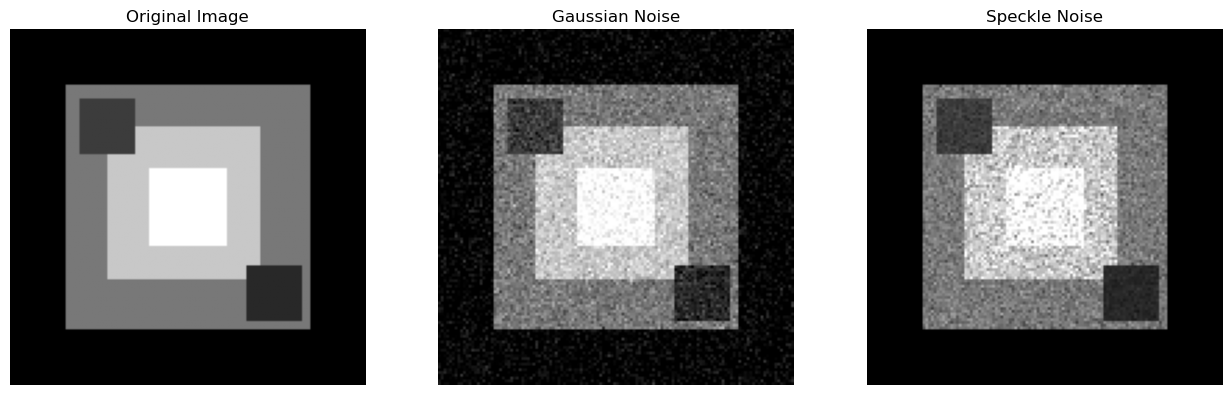

C:\Users\Rashmeet\anaconda3\Lib\site-packages\scipy\signal\_signaltools.py:1673: RuntimeWarning: divide by zero encountered in divide
  res *= (1 - noise / lVar)
C:\Users\Rashmeet\anaconda3\Lib\site-packages\scipy\signal\_signaltools.py:1673: RuntimeWarning: invalid value encountered in multiply
  res *= (1 - noise / lVar)


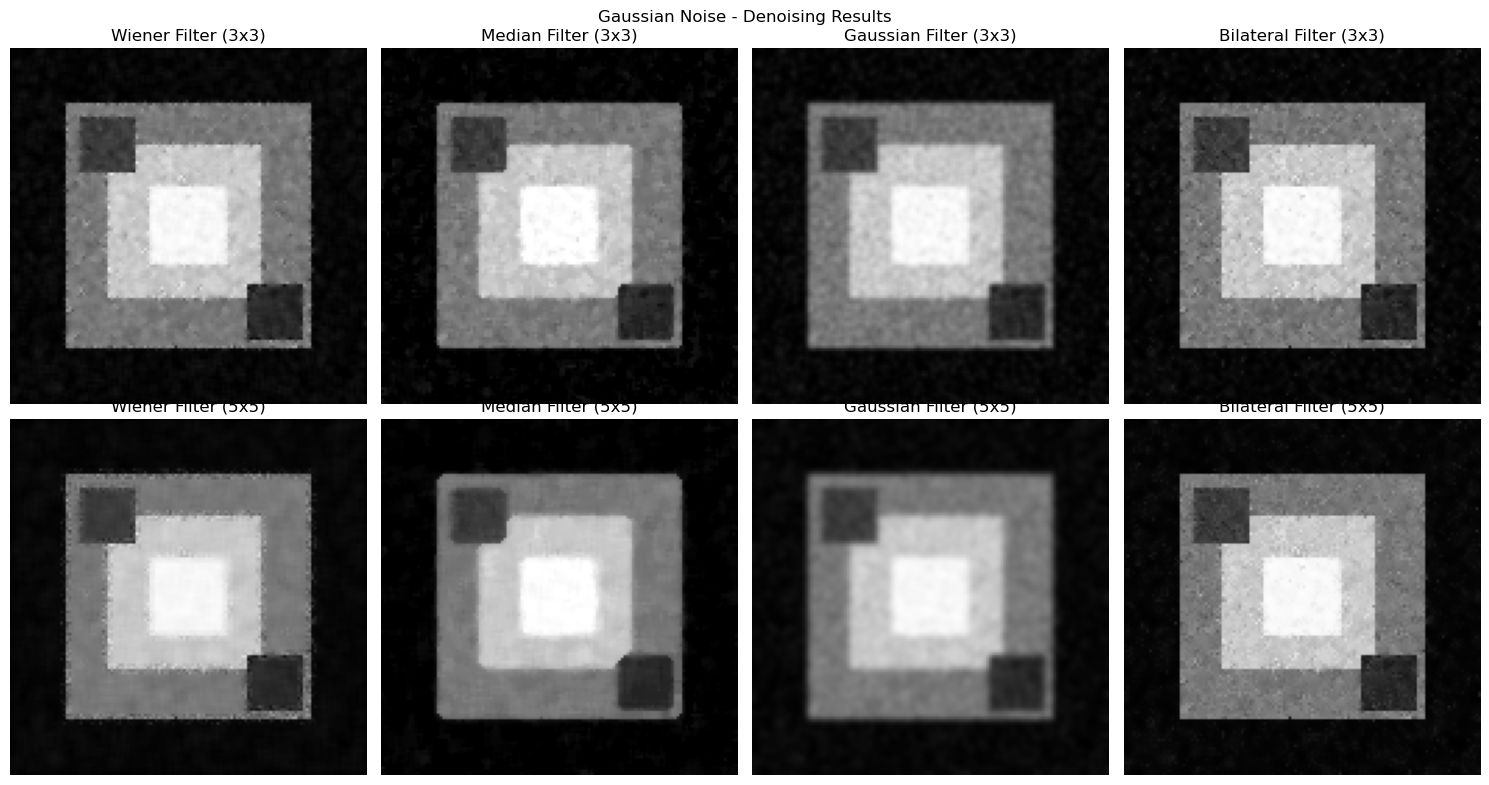

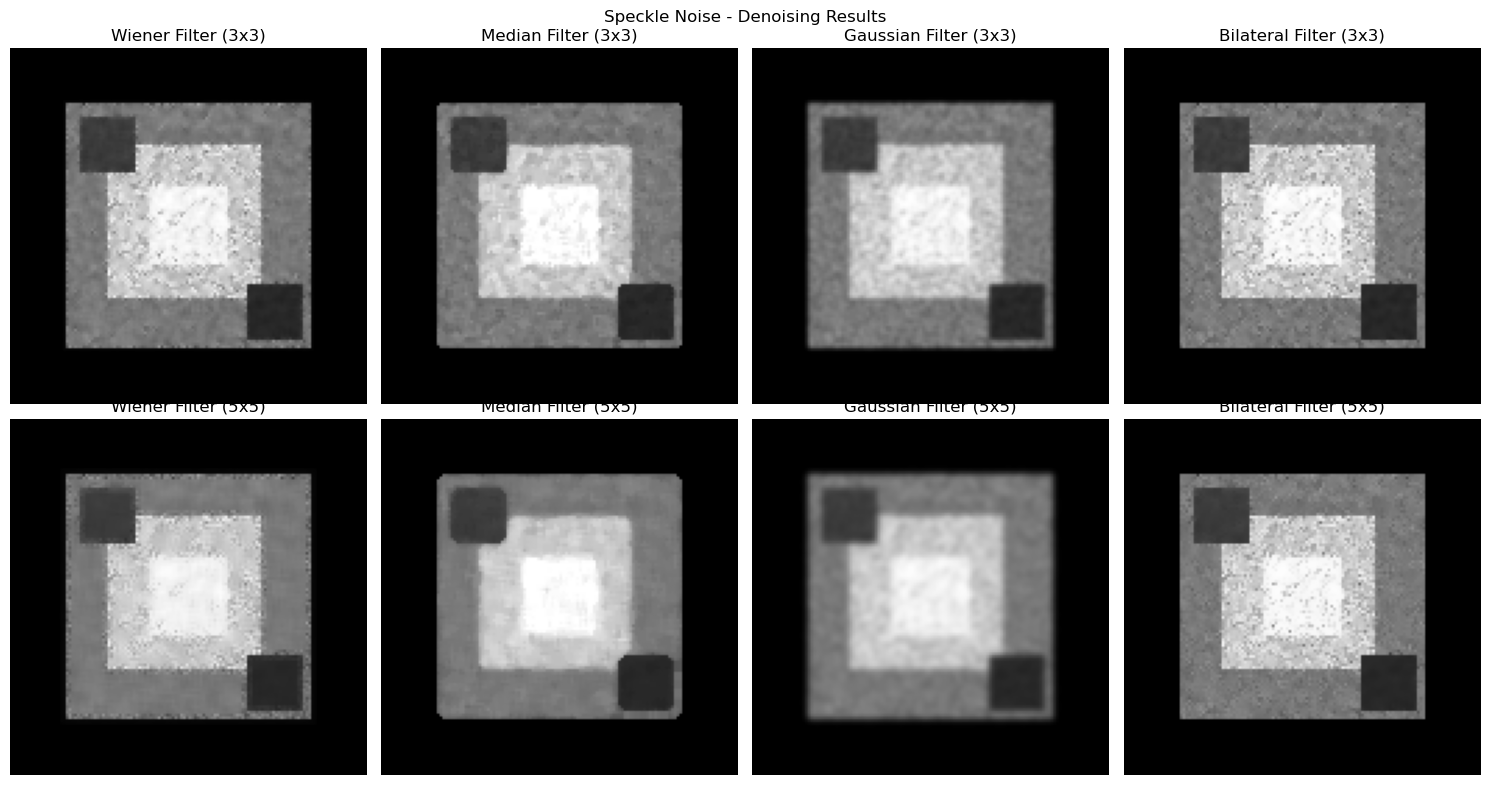

PSNR COMPARISON
---------------------------------------------------------------------------
Noise Type         Filter         Size     PSNR (dB)   
---------------------------------------------------------------------------
Gaussian Noise     Wiener         3x3     28.43
Gaussian Noise     Wiener         5x5     28.52
Gaussian Noise     Median         3x3     29.41
Gaussian Noise     Median         5x5     29.15
Gaussian Noise     Gaussian       3x3     26.83
Gaussian Noise     Gaussian       5x5     25.66
Gaussian Noise     Bilateral      3x3     28.19
Gaussian Noise     Bilateral      5x5     29.05
Speckle Noise      Wiener         3x3     28.77
Speckle Noise      Wiener         5x5     29.55
Speckle Noise      Median         3x3     30.14
Speckle Noise      Median         5x5     29.68
Speckle Noise      Gaussian       3x3     28.12
Speckle Noise      Gaussian       5x5     26.59
Speckle Noise      Bilateral      3x3     28.20
Speckle Noise      Bilateral      5x5     28.92


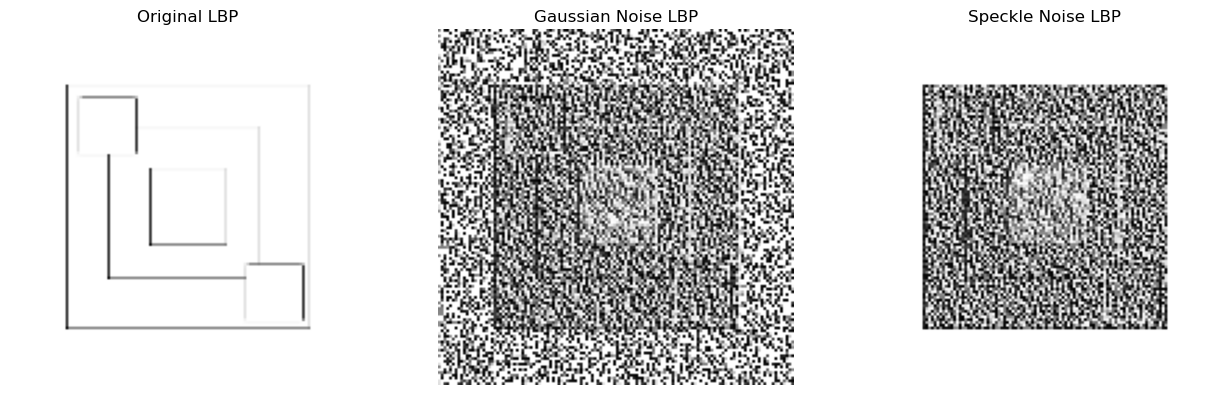

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import median_filter, gaussian_filter, uniform_filter
from scipy.signal import wiener

rng = np.random.default_rng(42)

# Generate synthetic grayscale image
size = 128
image = np.zeros((size, size), dtype=float)

image[20:108, 20:108] = 120
image[35:90, 35:90] = 200
image[50:78, 50:78] = 255

image[25:45, 25:45] = 60
image[85:105, 85:105] = 40

# Add Gaussian noise
gaussian_noisy = image + rng.normal(0, 20, image.shape)
gaussian_noisy = np.clip(gaussian_noisy, 0, 255)

# Add speckle noise
speckle_noisy = image + image * rng.normal(0, 0.15, image.shape)
speckle_noisy = np.clip(speckle_noisy, 0, 255)


# PSNR calculation
def calculate_psnr(original, processed):
    mse = np.mean((original - processed) ** 2)
    if mse == 0:
        return float("inf")
    return 10 * np.log10((255 ** 2) / mse)


# Median filter
def apply_median(img, size):
    return median_filter(img, size=size, mode="reflect")


# Gaussian filter
def apply_gaussian(img, size):
    sigma = 0.8 if size == 3 else 1.2
    return gaussian_filter(img, sigma=sigma, mode="reflect")


# Wiener filter
def apply_wiener(img, size):
    result = wiener(img, mysize=(size, size))
    return np.clip(result, 0, 255)


# Bilateral filter implementation
def bilateral_filter(img, size, sigma_color=30, sigma_space=1.5):
    radius = size // 2
    padded = np.pad(img, radius, mode="reflect")
    output = np.zeros_like(img)

    coordinates = np.arange(-radius, radius + 1)
    xx, yy = np.meshgrid(coordinates, coordinates)

    spatial_weights = np.exp(
        -(xx**2 + yy**2) / (2 * sigma_space**2)
    )

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            region = padded[i:i+size, j:j+size]
            center = padded[i+radius, j+radius]

            intensity_weights = np.exp(
                -((region - center)**2) / (2 * sigma_color**2)
            )

            weights = spatial_weights * intensity_weights
            output[i, j] = np.sum(weights * region) / np.sum(weights)

    return output


# Local Binary Pattern calculation
def calculate_lbp(img):
    padded = np.pad(img, 1, mode="edge")
    center = padded[1:-1, 1:-1]

    neighbors = [
        padded[:-2, :-2],
        padded[:-2, 1:-1],
        padded[:-2, 2:],
        padded[1:-1, 2:],
        padded[2:, 2:],
        padded[2:, 1:-1],
        padded[2:, :-2],
        padded[1:-1, :-2]
    ]

    lbp = np.zeros(img.shape, dtype=np.uint8)

    for bit, neighbor in enumerate(neighbors):
        lbp |= ((neighbor >= center).astype(np.uint8) << bit)

    return lbp


# Display original and noisy images
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, img, title in zip(
    axes,
    [image, gaussian_noisy, speckle_noisy],
    ["Original Image", "Gaussian Noise", "Speckle Noise"]
):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


# Apply filters for both noise types
filter_functions = {
    "Wiener": apply_wiener,
    "Median": apply_median,
    "Gaussian": apply_gaussian,
    "Bilateral": bilateral_filter
}

noisy_images = {
    "Gaussian Noise": gaussian_noisy,
    "Speckle Noise": speckle_noisy
}

results = {}

for noise_name, noisy_img in noisy_images.items():
    for filter_name, filter_function in filter_functions.items():
        for filter_size in [3, 5]:
            if filter_name == "Bilateral":
                filtered = filter_function(noisy_img, filter_size)
            else:
                filtered = filter_function(noisy_img, filter_size)

            results[(noise_name, filter_name, filter_size)] = filtered


# Display filtered results
for noise_name in noisy_images:
    fig, axes = plt.subplots(2, 4, figsize=(15, 8))

    for row, filter_size in enumerate([3, 5]):
        for col, filter_name in enumerate(filter_functions):
            filtered = results[(noise_name, filter_name, filter_size)]

            axes[row, col].imshow(
                filtered, cmap="gray", vmin=0, vmax=255
            )
            axes[row, col].set_title(
                f"{filter_name} Filter ({filter_size}x{filter_size})"
            )
            axes[row, col].axis("off")

    fig.suptitle(noise_name + " - Denoising Results")
    plt.tight_layout()
    plt.show()


# Calculate and display PSNR
print("PSNR COMPARISON")
print("-" * 75)
print(f"{'Noise Type':<18} {'Filter':<14} {'Size':<8} {'PSNR (dB)':<12}")
print("-" * 75)

for noise_name in noisy_images:
    for filter_name in filter_functions:
        for filter_size in [3, 5]:
            filtered = results[(noise_name, filter_name, filter_size)]
            psnr = calculate_psnr(image, filtered)

            print(
                f"{noise_name:<18} {filter_name:<14} "
                f"{filter_size}x{filter_size:<5} {psnr:.2f}"
            )


# LBP on original and noisy images
original_lbp = calculate_lbp(image)
gaussian_lbp = calculate_lbp(gaussian_noisy)
speckle_lbp = calculate_lbp(speckle_noisy)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, lbp_img, title in zip(
    axes,
    [original_lbp, gaussian_lbp, speckle_lbp],
    ["Original LBP", "Gaussian Noise LBP", "Speckle Noise LBP"]
):
    ax.imshow(lbp_img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()